# Online Shopping Behaviour: ML Model
Predict whether a respondent is a **regular online shopper** (monthly or more) vs **rarely/never**.

Place `Online_Shopping_Data.csv` in the same folder as this notebook.

In [13]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

## 1. Load data

In [14]:
df = pd.read_csv('Online Shopping Data.csv')
print(df.shape)
df.head()

(201, 17)


,Gender,Online_Shopping_Freq,Online_Purchase_Proportion,Review_Check_Freq,Attraction_Factor,Retailer_Choice_Factors,Preferred_Payment,Local_vs_Intl_Retailers,Preferred_Marketplace,Security_Concern_Level,Promo_Participation,Price_Sensitivity,Comfortable_Price_Range,Frequent_Products,Major_Drawback,Authenticity_Concern,Desired_Improvements
0,Male,Rarely or Never,0-20 %,Always,Ease and Comfort of shopping from home,Brand reputation and trustworthiness,Credit or debit card,"No preference, depends on the product",Daraz,Very concerned,Occasionally participate,Moderately price-sensitive,1k to 5k,Clothing and fashion accessories,"Yes, issues with product quality",Neutral or unsure,Enhanced customer reviews and ratings system
1,Female,Rarely or Never,0-20 %,Always,Attractive discounts and promotions,Product reviews and ratings,Cash on delivery (if available),"No preference, depends on the product",Others,Neutral,Rarely or Never participate,Slightly price-sensitive,1k to 5k,Clothing and fashion accessories,"No, I have not experienced any drawbacks",Neutral or unsure,Enhanced customer reviews and ratings system
2,Female,Once in a month,41-60 %,Always,Ease and Comfort of shopping from home,Brand reputation and trustworthiness,Cash on delivery (if available),"No preference, depends on the product",Daraz,Somewhat concerned,Frequently participate,Moderately price-sensitive,1k to 5k,Clothing and fashion accessories,"Yes, issues with product quality","Yes, always confident in product authenticity ...","Better product descriptions and images, Enhanc..."
3,Male,Once in a month,41-60 %,Always,Ease and Comfort of shopping from home,Product reviews and ratings,Cash on delivery (if available),Prefer local retailers,AliExpress,Somewhat concerned,Rarely or Never participate,Moderately price-sensitive,1k to 5k,Clothing and fashion accessories,"No, I have not experienced any drawbacks",Neutral or unsure,Better product descriptions and images
4,Female,Rarely or Never,0-20 %,Frequently,Ease and Comfort of shopping from home,Brand reputation and trustworthiness,Cash on delivery (if available),"No preference, depends on the product",Amazon,Very concerned,Rarely or Never participate,Moderately price-sensitive,less than 1k,"Books and media (e.g., movies, music)","Yes, issues with product quality","No, often concerned about product authenticity...","Better product descriptions and images, Improv..."


## 2. Clean data
Removes one corrupted row (date-like values), fixes a typo, and groups rare free-text answers.

In [15]:
freq_ok = ['Once in a month','Rarely or Never','Once in a week','Multiple times per week']
df = df[df['Online_Shopping_Freq'].isin(freq_ok)]
df = df[df['Gender'].isin(['Male','Female','Other'])]
df['Gender'] = df['Gender'].replace({'Other':'Other/Unspecified'})

top = df['Frequent_Products'].value_counts().index[:4]
df['Frequent_Products'] = df['Frequent_Products'].where(df['Frequent_Products'].isin(top), 'Other')
df['Major_Drawback'] = df['Major_Drawback'].where(df['Major_Drawback'].str.startswith(('Yes','No,')), 'Other')
good = ['Better product descriptions and images','Enhanced customer reviews and ratings system',
        'More personalized recommendations','Improved search and filtering options']
df['Desired_Improvements'] = df['Desired_Improvements'].apply(lambda s: s if s in good else 'Multiple/Other')
df['Local_vs_Intl_Retailers'] = df['Local_vs_Intl_Retailers'].str.replace('lnternational','International')
print('Rows after cleaning:', len(df))

Rows after cleaning: 200


## 3. Explore

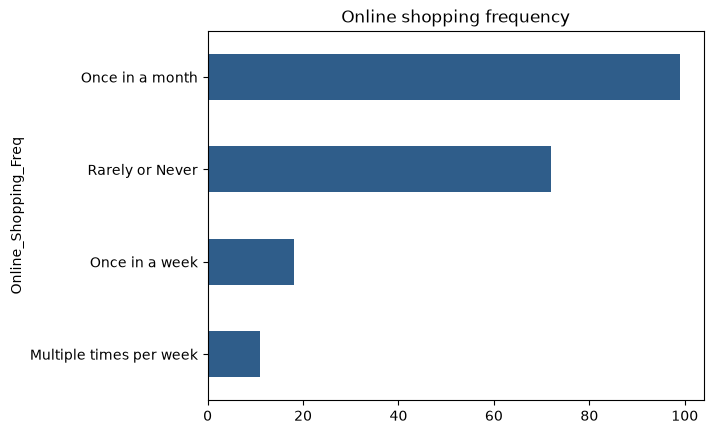

In [16]:
df['Online_Shopping_Freq'].value_counts().plot.barh(color='#2f5d8a', title='Online shopping frequency')
plt.gca().invert_yaxis(); plt.show()

In [17]:
# Share of regular shoppers by promotion participation and authenticity trust
df['Regular_Shopper'] = (df['Online_Shopping_Freq'] != 'Rarely or Never').astype(int)
for col in ['Promo_Participation','Authenticity_Concern','Gender']:
    print(df.groupby(col)['Regular_Shopper'].agg(['mean','count']).round(2), '\n')

                                                   mean  count
Promo_Participation                                           
Always take advantage of promotions and discounts  0.64     28
Frequently participate                             0.83     42
Occasionally participate                           0.70     66
Rarely or Never participate                        0.45     64 

                                                    mean  count
Authenticity_Concern                                           
Mostly confident, with occasional concerns          0.76     82
Neutral or unsure                                   0.55     62
No, often concerned about product authenticity ...  0.37     19
Yes, always confident in product authenticity a...  0.68     37 

                   mean  count
Gender                        
Female             0.71    125
Male               0.53     74
Other/Unspecified  0.00      1 



## 4. Prepare features
`Online_Purchase_Proportion` is excluded because it nearly duplicates the target (leakage).

In [18]:
y = df['Regular_Shopper']
X = df.drop(columns=['Regular_Shopper','Online_Shopping_Freq','Online_Purchase_Proportion'])
cats = list(X.columns)
pre = ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), cats)])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print(len(Xtr), 'train /', len(Xte), 'test')

150 train / 50 test


## 5. Compare models

In [19]:
models = {
 'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
 'Logistic Regression': LogisticRegression(max_iter=2000, C=0.3, class_weight='balanced'),
 'Random Forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight='balanced', random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    p = Pipeline([('pre', pre), ('m', m)])
    auc = cross_val_score(p, Xtr, ytr, cv=cv, scoring='roc_auc')
    p.fit(Xtr, ytr); fitted[name] = p
    pred = p.predict(Xte); proba = p.predict_proba(Xte)[:,1]
    rows.append(dict(Model=name, CV_AUC=auc.mean(), CV_AUC_sd=auc.std(),
                     Test_Acc=accuracy_score(yte,pred), Test_F1=f1_score(yte,pred), Test_AUC=roc_auc_score(yte,proba)))
results = pd.DataFrame(rows).round(3)
results

,Model,CV_AUC,CV_AUC_sd,Test_Acc,Test_F1,Test_AUC
0,Baseline (majority),0.500,0.000,0.64,0.780,0.500
1,Logistic Regression,0.706,0.052,0.74,0.800,0.766
2,Random Forest,0.693,0.061,0.72,0.781,0.767
3,Gradient Boosting,0.622,0.033,0.66,0.767,0.604


## 6. Final model: Logistic Regression

              precision    recall  f1-score   support

Rarely/Never       0.65      0.61      0.63        18
     Regular       0.79      0.81      0.80        32

    accuracy                           0.74        50
   macro avg       0.72      0.71      0.71        50
weighted avg       0.74      0.74      0.74        50



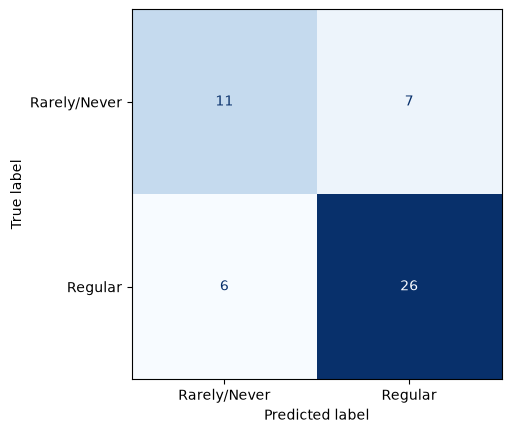

In [20]:
final = fitted['Logistic Regression']
pred = final.predict(Xte)
print(classification_report(yte, pred, target_names=['Rarely/Never','Regular']))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=['Rarely/Never','Regular']).plot(cmap='Blues', colorbar=False)
plt.show()

## 7. Feature importance (permutation, on test set)

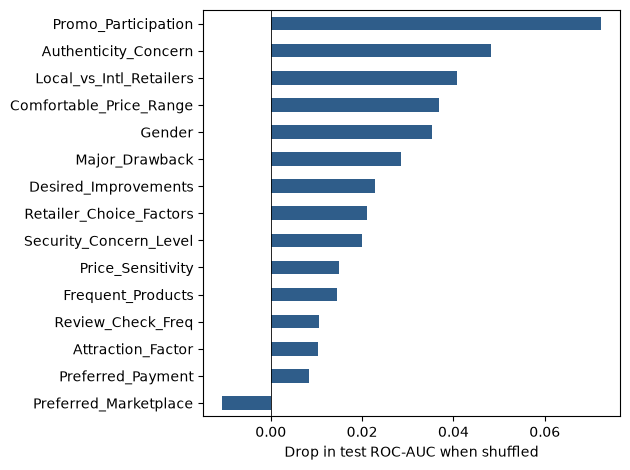

In [21]:
pi = permutation_importance(final, Xte, yte, scoring='roc_auc', n_repeats=50, random_state=42)
imp = pd.Series(pi.importances_mean, index=cats).sort_values()
imp.plot.barh(color='#2f5d8a'); plt.axvline(0, color='k', lw=0.6)
plt.xlabel('Drop in test ROC-AUC when shuffled'); plt.tight_layout(); plt.show()

## 8. Save model and try a prediction

In [22]:
joblib.dump(final, 'shopping_model.joblib')
sample = Xte.iloc[[0]]
print(sample.T)
print('Prob. regular shopper:', round(final.predict_proba(sample)[0,1], 3))

                                                                        99
Gender                                                              Female
Review_Check_Freq                                                   Always
Attraction_Factor                   Ease and Comfort of shopping from home
Retailer_Choice_Factors                        Product reviews and ratings
Preferred_Payment                                     Credit or debit card
Local_vs_Intl_Retailers              No preference, depends on the product
Preferred_Marketplace                                                Daraz
Security_Concern_Level                                Not Concerned at all
Promo_Participation      Always take advantage of promotions and discounts
Price_Sensitivity                               Not price sensitive at all
Comfortable_Price_Range                                           1k to 5k
Frequent_Products                         Clothing and fashion accessories
Major_Drawback           

**Notes:** small sample (~200) and 50 test rows, so metrics are uncertain (CV AUC varies about ±0.05).